<a href="https://colab.research.google.com/github/kaveeshasasi/Machine-Learning-Ex/blob/main/Machine-Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [2]:
!pip install scikit-learn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score,f1_score,
                             confusion_matrix, classification_report)
df = pd.read_csv('/content/train.csv')
print("Loaded:",df.shape)
df.head()

Loaded: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
print(df.info()) #columns and data types
print(df.describe(include="all")) #summeries
print(df.isnull().sum()) #missing values
print("Duplicates:",df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None
        PassengerId    Survived      Pclass                     Name   Sex  \
count    891.000000  891.000000  891.000000                      891   891   
unique          NaN         NaN         NaN                      891     2   
top  

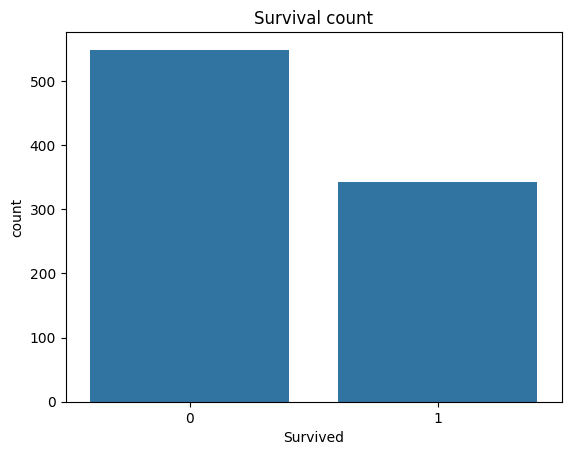

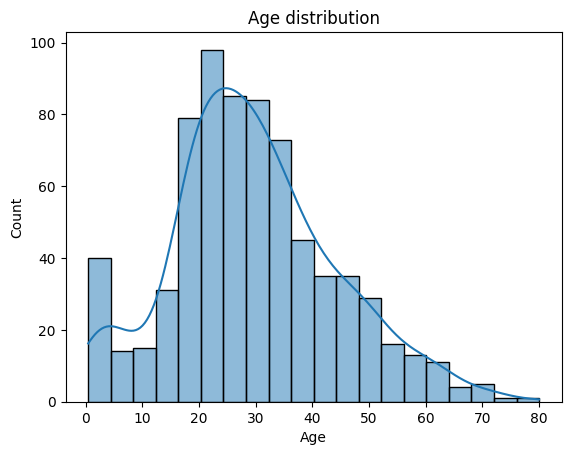

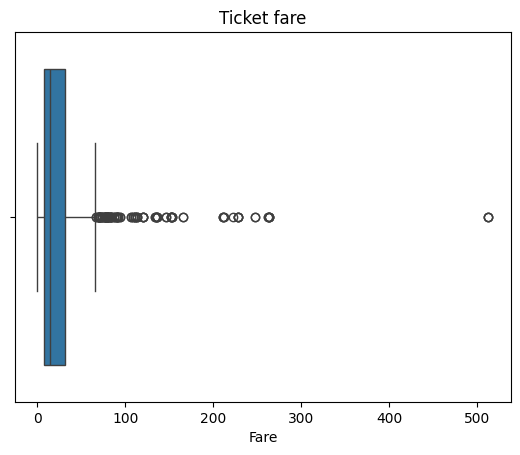

In [8]:
#1.How maby passengers survied?
sns.countplot(data=df, x="Survived")
plt.title("Survival count")
plt.show()

#2.Passenger age distribution
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Age distribution")
plt.show()

#3. Ticket fare and unusaual values
sns.boxplot(data=df, x="Fare")
plt.title("Ticket fare")
plt.show()

In [11]:
features = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
#Remove exact duplicate rows and rows wityh no target answers
df = df.drop_duplicates()
df = df.dropna(subset=["Survived"])
X = df[features] #input information
y = df["Survived"]#Answer we want to predict

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)
print("Training rows:",len(X_train))#row amount that the model is trained on
print("Testing rows:",len(X_test))#rows amount we are testing
#

Training rows: 712
Testing rows: 179


In [15]:
from types import prepare_class
numeric_cols = X_train.select_dtypes(
    include=np.number).columns.tolist()
text_cols = X_train.select_dtypes(
    exclude=np.number).columns.tolist()
    #For numbers: replace blanks with the training median
numeric_pipe=Pipeline([
        ("fill", SimpleImputer(strategy="median"))
    ])
    #For Text: fill blkanks with the most common values,
    #then turn categories into numeric columns
text_pipe=Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ])
preprocessor = ColumnTransformer([
        ("numbers", numeric_pipe, numeric_cols),
        ("text", text_pipe, text_cols)
    ])


In [16]:
#Create a machine learning pipeline to combine preprocessing and model training
model = Pipeline([
    #Apply the preprocessing steps to prepare the data before traing
        ("preprocess", preprocessor),
    #Create the random forest classification model
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        ))
    ])
#Train the complete pipelinge using the training input data(X_train) and the correct answers(y_train)
model.fit(X_train, y_train)
#Display a message to fonfirm that training has finished
print("Training complete!")

Training complete!


In [17]:
#Predict the answers for the unseen test records
y_pred = model.predict(X_test)
#Calculate evaluation scores
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred,zero_division=0))
print("Recall:", recall_score(y_test, y_pred,zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred,zero_division=0))
print(classification_report(y_test, y_pred,zero_division=0))

Accuracy: 0.8268156424581006
Precision: 0.8166666666666667
Recall: 0.7101449275362319
F1 Score: 0.7596899224806202
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179

